# What is different in breast cancer?

**Breast cancer** is the most common cancer in women. In the project **The Cancer Genome Atlas (TCGA)**, researchers sequenced tumours of over 1,000 patients, and for some of them also **normal breast tissue** from near the tumour. All this data is public.

You get the data of **10 patients**: from each, one sample of the tumour and one of normal tissue, so **20 samples**. Unlike mice or cells in a lab, these are real people of different ages, with different kinds of tumours. Expect the data to be messier!

### Your research question

> Which genes are different between breast tumours and normal breast tissue of the same patients? What do they tell you about what cancer cells do?

The data set is called `"cancer"`.

In [1]:
setLanguage("en")   # language of the messages and plots below

Language: English



In [2]:
data <- loadDataset("cancer")
data$samples

Loaded data set 'cancer': 19944 genes, 20 samples.



,sample,patient,tissue
,<chr>,<fct>,<fct>
A7_A0CE_normal,A7_A0CE_normal,A7_A0CE,normal
A7_A0CH_normal,A7_A0CH_normal,A7_A0CH,normal
A7_A0D9_normal,A7_A0D9_normal,A7_A0D9,normal
A7_A13F_normal,A7_A13F_normal,A7_A13F,normal
AC_A23H_normal,AC_A23H_normal,AC_A23H,normal
AC_A2FB_normal,AC_A2FB_normal,AC_A2FB,normal
AC_A2FF_normal,AC_A2FF_normal,AC_A2FF,normal
AC_A2FM_normal,AC_A2FM_normal,AC_A2FM,normal
BH_A0AU_normal,BH_A0AU_normal,BH_A0AU,normal


### Your steps

Work through the same steps as in the tutorial. You can copy code from `01_tutorial_milk.ipynb` and change it: the **column names** and **group names** are different here. Below each step there is a cell for your code, and a hint you can open if you get stuck.

| Step | Functions from the tutorial |
|---|---|
| 1 Look at the data | `DGEList`, `plotLibrarySizes` |
| 2 Define the groups | `dge$samples$group <- …`, `table`, `plotGene` |
| 3 Prepare | `filterByExpr`, `normLibSizes`, `plotDistributions`, `plotSamples` |
| 4 Design and contrast | `model.matrix`, `makeContrasts` |
| 5 Test | `voom`, `lmFit`, `contrasts.fit`, `eBayes`, `decideTests` |
| 6 Interpret | `plotVolcano`, `showTop`, `plotGene` |

If a cell gives an error, read the message, check the spelling of the names, and make sure you ran the cells above.

## 1 Look at the data

Make a `DGEList` and look at the library sizes.

[1] 19944    20

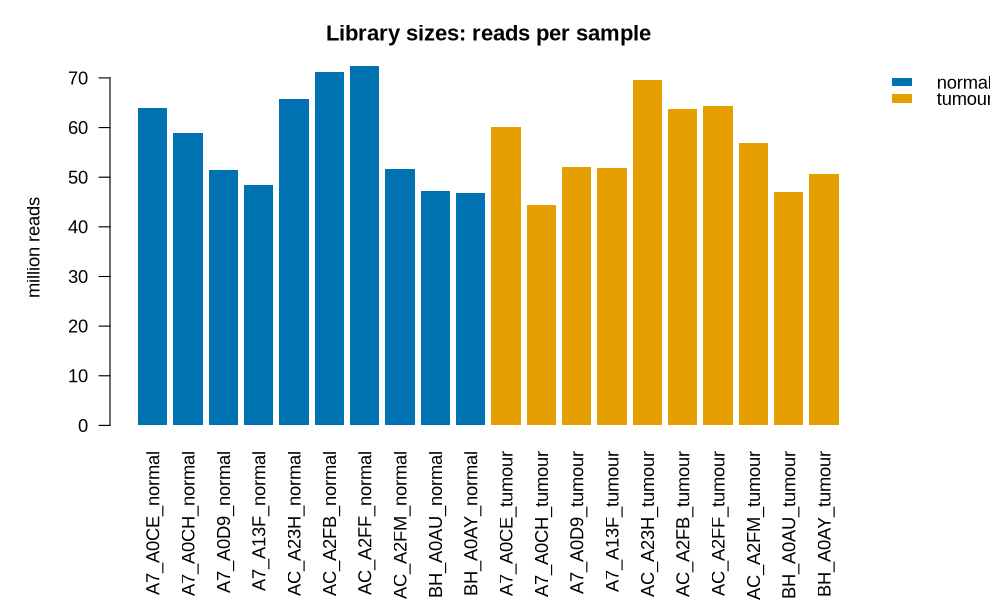

In [3]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dim(dge)
plotLibrarySizes(dge, colour_by = "tissue")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

As in the tutorial. Colour by `"tissue"`.

</details>

## 2 Define the groups

Set the groups (column `tissue`). Then look at a gene that every growing tissue needs: **MKI67** is only made by cells that are **dividing**.


normal tumour 
    10     10 

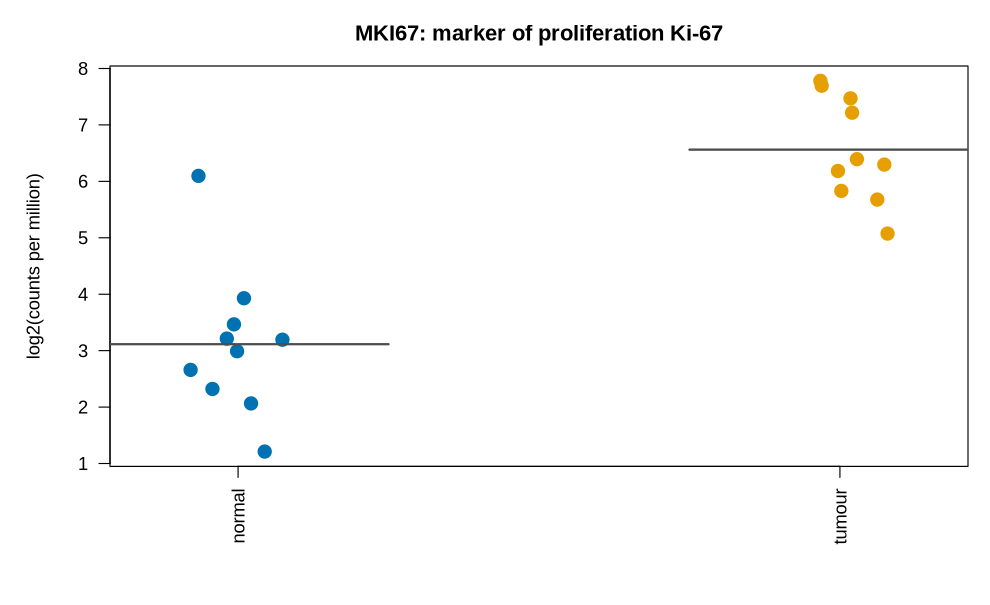

In [4]:
dge$samples$group <- dge$samples$tissue
table(dge$samples$group)
plotGene(dge, "MKI67", group_by = "tissue")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

`dge$samples$group <- dge$samples$tissue`, then `plotGene(dge, "MKI67", group_by = "tissue")`.

</details>

## 3 Prepare

Filter, normalise and draw the sample map, coloured by tissue and labelled by patient.

[1] 15580    20

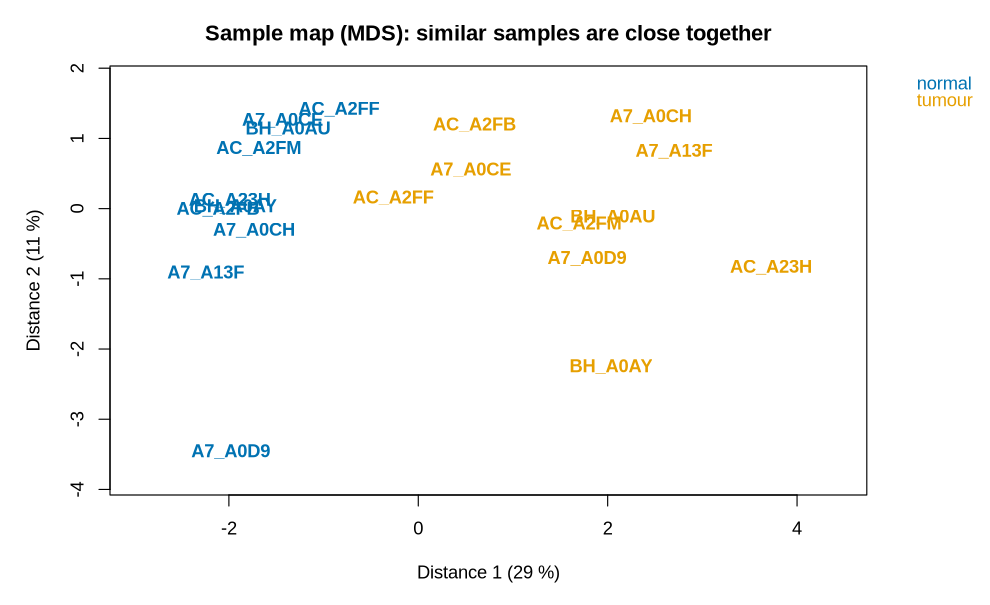

In [5]:
keep <- filterByExpr(dge)
dge <- dge[keep, , keep.lib.sizes = FALSE]
dge <- normLibSizes(dge)
dim(dge)
plotSamples(dge, colour_by = "tissue", label_by = "patient")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

As part 3 of the tutorial, with `plotSamples(dge, colour_by = "tissue", label_by = "patient")`.

</details>

**Question: Are the normal samples and the tumour samples separated? Which group is more spread out, and why could that be?**

✅ **Answer:** Distance 1 (29 %) mostly separates **normal tissue (left)** from **tumours (right)**. The normal samples lie close together, the tumours are spread widely: every tumour is different (different mutations, different types of breast cancer). One tumour (AC_A2FF) lies close to the normal samples; it may contain a lot of normal tissue.

## 4 Design and contrast

Each patient gave a tumour **and** a normal sample: what kind of experiment is that? Think back to what you know about **paired** designs (or read the hint), then write the design and the contrast `tumour_vs_normal`.

In [6]:
design <- model.matrix(~0 + tissue + patient, data = dge$samples)
colnames(design)
contrasts <- makeContrasts(tumour_vs_normal = tissuetumour - tissuenormal, levels = design)

[1] "tissuenormal"   "tissuetumour"   "patientA7_A0CH" "patientA7_A0D9" "patientA7_A13F" "patientAC_A23H"
 [7] "patientAC_A2FB" "patientAC_A2FF" "patientAC_A2FM" "patientBH_A0AU" "patientBH_A0AY"

<details><summary>💡 <b>Hint</b> (click to open)</summary>

A paired design: add the patient to the design so each tumour is compared with the normal tissue of the **same** patient: `model.matrix(~0 + tissue + patient, data = dge$samples)`. The contrast uses the columns `tissuetumour` and `tissuenormal`.

</details>

## 5 Test

Test every gene and count the significant ones.

       tumour_vs_normal
Down               2352
NotSig            11146
Up                 2082

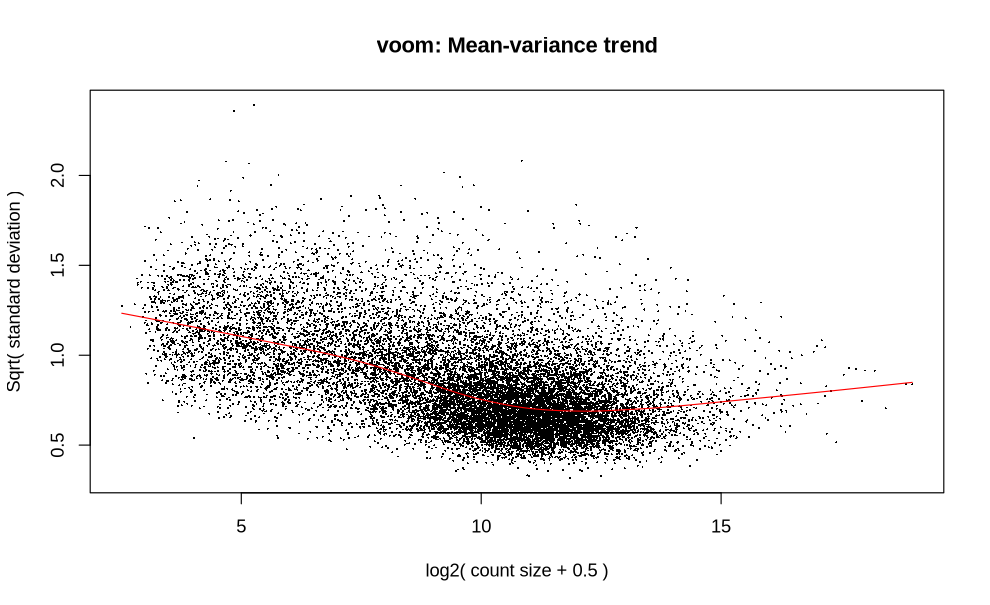

In [7]:
v <- voom(dge, design, plot = TRUE)
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)
summary(decideTests(fit))

<details><summary>💡 <b>Hint</b> (click to open)</summary>

The cells from part 5 of the tutorial work unchanged.

</details>

**Question: How many genes are significant? Is that a list you can still read through?**

✅ **Answer:** About **2,100 up** and **2,350 down**: far too many to read. We need to **prioritise**: look at the strongest changes first (volcano plot, `showTop`), or ask for genes that change by a lot (see the bonus).

## 6 Interpret

Draw the volcano plot and list the top genes going up and down. Look some of them up on [GeneCards](https://www.genecards.org). Try to sort them into a few **themes**.

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
COL10A1,collagen type X alpha 1 chain,7.15,142.4× higher,3.1,8.8e-06
SLC24A2,solute carrier family 24 member 2,5.83,56.9× higher,-1.2,3.1e-05
TNNT1,"troponin T1, slow skeletal type",4.57,23.8× higher,1.3,8.8e-05
NUF2,NUF2 component of NDC80 kinetochore complex,3.22,9.3× higher,1.8,9.3e-05
MMP11,matrix metallopeptidase 11,5.28,38.8× higher,5.2,9.3e-05
ERCC6L,"ERCC excision repair 6 like, spindle assemb…",3.02,8.1× higher,1.2,9.3e-05
ASPM,assembly factor for spindle microtubules,3.86,14.5× higher,2.7,9.4e-05
RAMP1,receptor activity modifying protein 1,3.56,11.8× higher,2.9,9.4e-05
INHBA,inhibin subunit beta A,3.82,14.1× higher,4.3,9.4e-05


symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
JPH2,junctophilin 2,-3.42,10.7× lower,3.4,2.3e-05
FGF1,fibroblast growth factor 1,-2.43,5.4× lower,4.9,2.7e-05
MME,membrane metalloendopeptidase,-3.91,15.1× lower,5.9,3.1e-05
HPSE2,heparanase 2 (inactive),-4.33,20.1× lower,1.4,6.0e-05
PAMR1,peptidase domain containing associated with…,-4.23,18.7× lower,4.2,6.0e-05
LRRC3B,leucine rich repeat containing 3B,-4.52,23.0× lower,-1.2,7.7e-05
SCGB3A1,secretoglobin family 3A member 1,-4.87,29.2× lower,1.7,8.3e-05
KLHL29,kelch like family member 29,-2.97,7.8× lower,3.3,8.3e-05
APCDD1L,APC down-regulated 1 like,-3.29,9.8× lower,2.1,8.3e-05


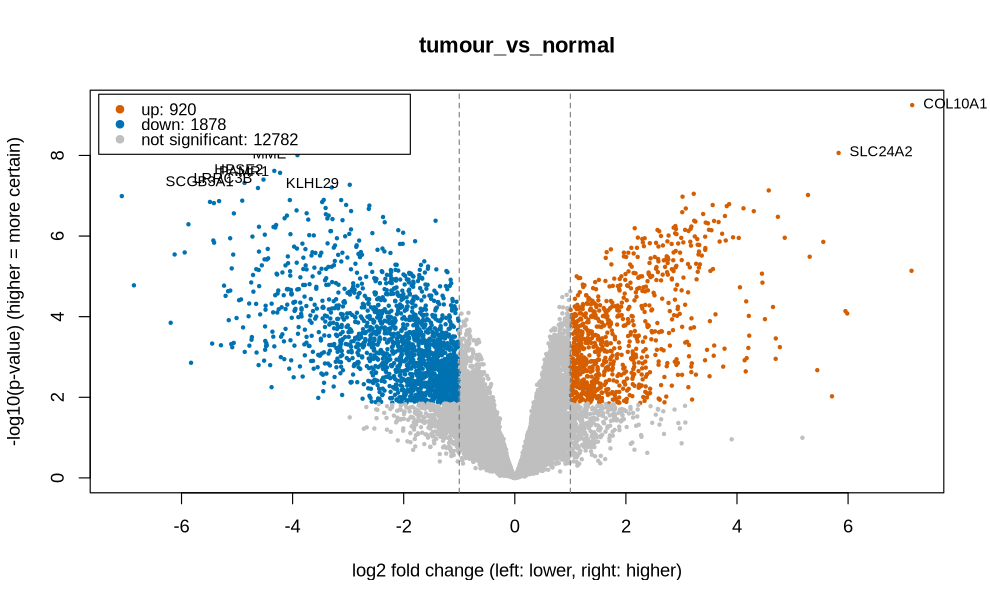

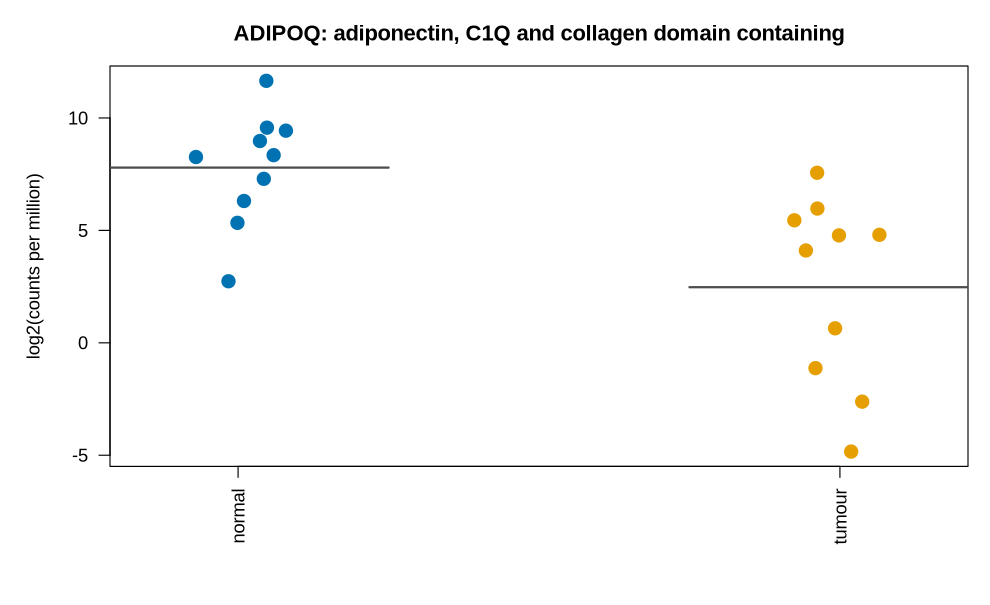

In [8]:
plotVolcano(fit, "tumour_vs_normal")
showTop(fit, "tumour_vs_normal", n = 20, direction = "up")
showTop(fit, "tumour_vs_normal", n = 20, direction = "down")
plotGene(dge, "ADIPOQ", group_by = "tissue")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

Possible themes: **cell division** (look for kinesins *KIF…*, *ASPM*, *NUF2*, *NEK2*, *TOP2A*), **remodelling the tissue around the tumour** (collagens *COL…*, matrix metalloproteinases *MMP…*), and on the "down" side: what is normal breast tissue mostly made of? Try `plotGene` with **ADIPOQ** and **LEP**.

</details>

## Your conclusion

Answer the research question in a few sentences: what did you compare, what did you find, and what does it mean? Be ready to show your volcano plot and your answer to the class.

✅ **Answer:** We compared tumour and normal breast tissue of 10 patients with a paired design. About 2,100 genes went up and 2,350 down. Up: many genes for **cell division** (*NUF2*, *ASPM*, *KIF4A*, *NEK2*, *MKI67*, *TOP2A*): cancer cells divide uncontrollably. Also up: genes that **rebuild the tissue around the tumour** (*COL10A1*, *MMP11*, *INHBA*), which helps tumours grow and invade. Down: genes of **fat tissue** (*ADIPOQ*, *LEP*), because normal breast tissue is mostly fat and the tumour pushes it aside, and genes of the normal milk ducts (*SCGB3A1*, *MME*). Genes like *ESR1* (oestrogen receptor) and *ERBB2* (HER2) vary strongly between patients: breast cancer is not one disease, which is why treatment is chosen per patient.

## Bonus 1: only the big changes

With thousands of significant genes, you can ask a stricter question: which genes change **at least 4-fold** (log fold change of 2)? `treat` tests exactly that.

In [9]:
fit_strict <- treat(fit, lfc = 2)
summary(decideTests(fit_strict))
showTop(fit_strict, "tumour_vs_normal", n = 30)

       tumour_vs_normal
Down                 20
NotSig            15552
Up                    8

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
COL10A1,collagen type X alpha 1 chain,7.15,142.4× higher,3.1,0.00023
SLC24A2,solute carrier family 24 member 2,5.83,56.9× higher,-1.2,0.00440
SMYD1,SET and MYND domain containing 1,-7.07,134.8× lower,0.5,0.01100
SCGB3A1,secretoglobin family 3A member 1,-4.87,29.2× lower,1.7,0.01900
MMP11,matrix metallopeptidase 11,5.28,38.8× higher,5.2,0.01900
VEGFD,vascular endothelial growth factor D,-5.49,44.9× lower,2.4,0.01900
OXTR,oxytocin receptor,-5.42,42.7× lower,4.9,0.01900
FABP7,fatty acid binding protein 7,-5.32,40.0× lower,0.1,0.01900
HPSE2,heparanase 2 (inactive),-4.33,20.1× lower,1.4,0.01900


## Bonus 2: every tumour is different

Look at **ESR1** (the oestrogen receptor) and **ERBB2** (HER2) with `plotGene`. Doctors test these two in every breast tumour. What do you see?

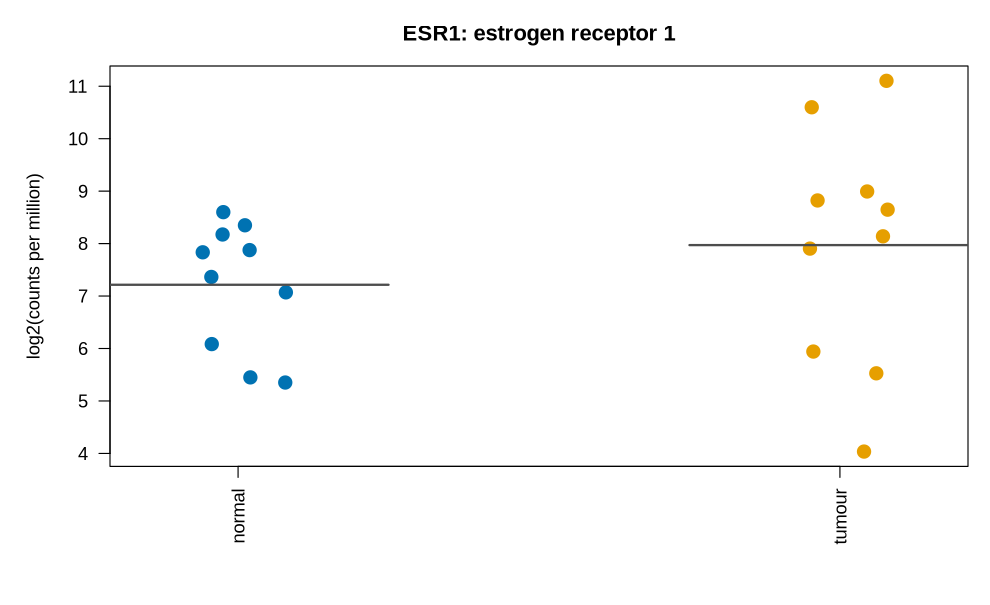

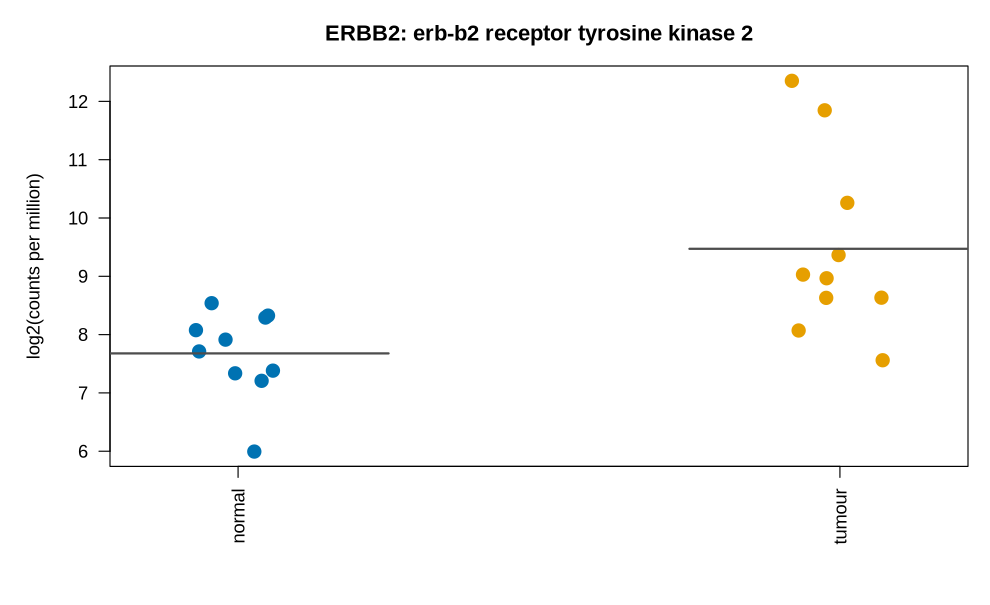

In [10]:
plotGene(dge, "ESR1", group_by = "tissue")
plotGene(dge, "ERBB2", group_by = "tissue")

✅ **Answer:** With `treat` only about **28** genes remain: a short list of the biggest changes. ESR1 is high in some tumours and very low in others; on average there is no significant difference. ERBB2 is very high in a few tumours only. These patients have different **types** of breast cancer: oestrogen-receptor-positive tumours can be treated with anti-hormone drugs, HER2-positive ones with antibodies against HER2. A comparison of averages can hide such differences between patients.

<small>Software: limma (Ritchie et al. 2015) with voom (Law et al. 2014) and edgeR (Chen et al. 2025) in R. Full sources for all data sets at the end of `01_tutorial_milk.ipynb`.</small>